<a href="https://colab.research.google.com/github/aliuahmad/30DaysOfPython-Arewa/blob/main/Vaccination_Campaign_ML_Projec.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data-Driven Analysis and Machine Learning Prediction of Vaccination Campaign Performance

**Researcher:** Ahmad Aliyu

**Research Area:** Data Science and Machine Learning

**Programming Language:** Python

**Development Environment:** Google Colab

## 1. Introduction

Vaccination campaigns are important public health interventions aimed at preventing vaccine-preventable diseases. However, campaign performance can vary across geographical locations due to differences in population coverage, accessibility, logistics, community participation and operational challenges.

This project applies data analysis and machine learning techniques to examine vaccination campaign performance, identify factors associated with campaign outcomes, and develop predictive models that can support evidence-based decision-making.

## 2. Project Objectives

1. Analyse vaccination campaign performance indicators.
2. Identify geographical and operational variations in campaign outcomes.
3. Examine factors associated with vaccination coverage.
4. Develop machine learning models to predict campaign performance.
5. Provide data-driven recommendations for improving future vaccination campaigns.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Machine Learning

In [ ]:
from google.colab import files

uploaded_more = files.upload()

In [ ]:
!pip install pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 15.1 MB/s  0:00:00


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_spss(filename)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

NameError: name 'uploaded' is not defined

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving INDIVIDUAL.sav to INDIVIDUAL.sav


In [4]:
from google.colab import files

uploaded_more = files.upload()

Saving IDENTIFICATION.sav to IDENTIFICATION.sav
Saving ROSTER.sav to ROSTER.sav


In [5]:
import os

print("Files currently in Colab:")
print(os.listdir())

Files currently in Colab:
['.config', 'ROSTER.sav', 'IDENTIFICATION.sav', 'INDIVIDUAL.sav', 'sample_data']


In [6]:
import os

print("Files currently in Colab:")
print(os.listdir())

Files currently in Colab:
['.config', 'ROSTER.sav', 'IDENTIFICATION.sav', 'INDIVIDUAL.sav', 'sample_data']


In [7]:
import pandas as pd

individual = pd.read_spss("INDIVIDUAL.sav")
identification = pd.read_spss("IDENTIFICATION.sav")
roster = pd.read_spss("ROSTER.sav")

print("INDIVIDUAL:", individual.shape)
print("IDENTIFICATION:", identification.shape)
print("ROSTER:", roster.shape)

ReadstatError: Unable to convert string to the requested encoding (invalid byte sequence)

In [12]:
import pyreadstat

individual, metadata = pyreadstat.read_sav(
    "INDIVIDUAL.sav",
    encoding="latin1"
)

print("Dataset loaded successfully!")
print("Rows and columns:", individual.shape)
print("Variables:")
print(individual.columns.tolist())

Dataset loaded successfully!
Rows and columns: (14313, 65)
Variables:
['hm03', 'hm00', 'state_code', 'state_name', 'lga_code', 'lga_name', 'ea_name', 'ea_code', 'sector', 'hm09', 'hm21', 'hm22', 's1a09d', 's1a09m', 's1a09y', 'line_resp_child', 'conscent_child', 'response_status', 'sia10h', 'sia10m', 'd1a', 'd1b', 'd1c', 'd2years', 'd2', 's1a16', 's1a17', 'sia17a', 's1a18', 's1a19', 's1a20', 's1a21', 's1a22', 's1a23', 's1a24a', 's1a24b', 's1a24c', 's1a24d', 's1a24e', 's1a24f', 's1a24g', 's1a24h', 's1a24i', 's1a24j', 's1a24k', 's1a24l', 's1a24m', 's1a24n', 's1a24o', 's1a24p', 's1a24sspc', 's1a25', 's1a26', 's1a27', 'sia28', 'sia31', 'sia32', 's1a35h', 's1a35m', 's1a20c', 'sia26a', 's1a27b', 'sia28b', 'sia30a', 'sia30b']


In [15]:
identification, id_metadata = pyreadstat.read_sav(
    "IDENTIFICATION.sav",
    encoding="latin1"
)

roster, roster_metadata = pyreadstat.read_sav(
    "ROSTER.sav",
    encoding="latin1"
)

print("IDENTIFICATION:", identification.shape)
print("ROSTER:", roster.shape)

IDENTIFICATION: (15229, 25)
ROSTER: (67371, 22)


In [16]:
for i, column in enumerate(individual.columns, 1):
    print(i, column)

1 hm03
2 hm00
3 state_code
4 state_name
5 lga_code
6 lga_name
7 ea_name
8 ea_code
9 sector
10 hm09
11 hm21
12 hm22
13 s1a09d
14 s1a09m
15 s1a09y
16 line_resp_child
17 conscent_child
18 response_status
19 sia10h
20 sia10m
21 d1a
22 d1b
23 d1c
24 d2years
25 d2
26 s1a16
27 s1a17
28 sia17a
29 s1a18
30 s1a19
31 s1a20
32 s1a21
33 s1a22
34 s1a23
35 s1a24a
36 s1a24b
37 s1a24c
38 s1a24d
39 s1a24e
40 s1a24f
41 s1a24g
42 s1a24h
43 s1a24i
44 s1a24j
45 s1a24k
46 s1a24l
47 s1a24m
48 s1a24n
49 s1a24o
50 s1a24p
51 s1a24sspc
52 s1a25
53 s1a26
54 s1a27
55 sia28
56 sia31
57 sia32
58 s1a35h
59 s1a35m
60 s1a20c
61 sia26a
62 s1a27b
63 sia28b
64 sia30a
65 sia30b


In [19]:
for name, label in zip(
    metadata.column_names,
    metadata.column_labels
):
    print(f"{name}: {label}")

hm03: None
hm00: ZONE
state_code: STATE_CODE
state_name: STATE_NAME
lga_code: LGA_CODE
lga_name: LGA_NAME
ea_name: EA_NAME
ea_code: EA_CODE
sector: AREA/SECTOR
hm09: Household Number
hm21: Child Line number
hm22: Child Name
s1a09d: Day of interview
s1a09m: Month of interview
s1a09y: Year of interview
line_resp_child: LINE NUMBER OF RESPONDENT
conscent_child: Conscent
response_status: Response status
sia10h: hours
sia10m: minutes
d1a: Day
d1b: Month
d1c: Year
d2years: AGE IN YERAS
d2: Age
s1a16: SIA16. HAS (NAME) EVER RECEIVED ANY VACCINATIONS TO PREVENT (HIM/HER) FROM GETTI
s1a17: SIA17. WAS THE CHILD LIVING HERE DURING THE CAMPAIGN? (MEASLES AND MENA VACCINAT
sia17a: SIA17A. PLEASE SPECIFY WHERE THE CHILD WAS LIVING.
s1a18: SIA18 WHAT WAS THE MAIN SOURCE OF INFORMATION ABOUT THE CAMPAIGN?
s1a19: SIA19. WHAT WAS THE PRIMARY SOURCE OF INFORMATION ABOUT THE OCCURRENCE OF THE CA
s1a20: SIA20. DID THE CHILD RECEIVE THE MEASLES VACCINE DURING THE RECENT CAMPAIGN (MEA
s1a21: SIA21. DID THE C

In [20]:
for name, label in zip(
    metadata.column_names,
    metadata.column_labels
):
    print(f"{name}: {label}")

hm03: None
hm00: ZONE
state_code: STATE_CODE
state_name: STATE_NAME
lga_code: LGA_CODE
lga_name: LGA_NAME
ea_name: EA_NAME
ea_code: EA_CODE
sector: AREA/SECTOR
hm09: Household Number
hm21: Child Line number
hm22: Child Name
s1a09d: Day of interview
s1a09m: Month of interview
s1a09y: Year of interview
line_resp_child: LINE NUMBER OF RESPONDENT
conscent_child: Conscent
response_status: Response status
sia10h: hours
sia10m: minutes
d1a: Day
d1b: Month
d1c: Year
d2years: AGE IN YERAS
d2: Age
s1a16: SIA16. HAS (NAME) EVER RECEIVED ANY VACCINATIONS TO PREVENT (HIM/HER) FROM GETTI
s1a17: SIA17. WAS THE CHILD LIVING HERE DURING THE CAMPAIGN? (MEASLES AND MENA VACCINAT
sia17a: SIA17A. PLEASE SPECIFY WHERE THE CHILD WAS LIVING.
s1a18: SIA18 WHAT WAS THE MAIN SOURCE OF INFORMATION ABOUT THE CAMPAIGN?
s1a19: SIA19. WHAT WAS THE PRIMARY SOURCE OF INFORMATION ABOUT THE OCCURRENCE OF THE CA
s1a20: SIA20. DID THE CHILD RECEIVE THE MEASLES VACCINE DURING THE RECENT CAMPAIGN (MEA
s1a21: SIA21. DID THE C

In [21]:
# Examine the two vaccination outcome variables

for column in ["s1a20", "s1a20c"]:
    print("\nVARIABLE:", column)

    print("\nResponse counts:")
    print(individual[column].value_counts(dropna=False))

    print("\nValue labels:")
    print(metadata.variable_value_labels.get(column, "No value labels found"))


VARIABLE: s1a20

Response counts:
s1a20
1.0     6966
NaN     5986
2.0     1327
99.0      34
Name: count, dtype: int64

Value labels:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}

VARIABLE: s1a20c

Response counts:
s1a20c
NaN     8235
1.0     4086
2.0     1901
99.0      91
Name: count, dtype: int64

Value labels:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}


In [22]:
print("Number of states:", individual["state_name"].nunique())
print("Number of LGAs:", individual["lga_name"].nunique())

print("\nRecords by state:")
print(individual["state_name"].value_counts())

Number of states: 26
Number of LGAs: 511

Records by state:
state_name
YOBE           2942
BORNO          1866
LAGOS          1270
BAUCHI          603
JIGAWA          600
ZAMFARA         556
GOMBE           537
ADAMAWA         476
NIGER           470
PLATEAU         457
NASARAWA        447
CROSS RIVER     355
KOGI            352
ANAMBRA         347
BENUE           346
ONDO            341
AKWA IBOM       282
FCT             274
OGUN            252
DELTA           244
OSUN            242
OYO             237
EDO             229
ENUGU           226
RIVERS          204
EKITI           158
Name: count, dtype: int64


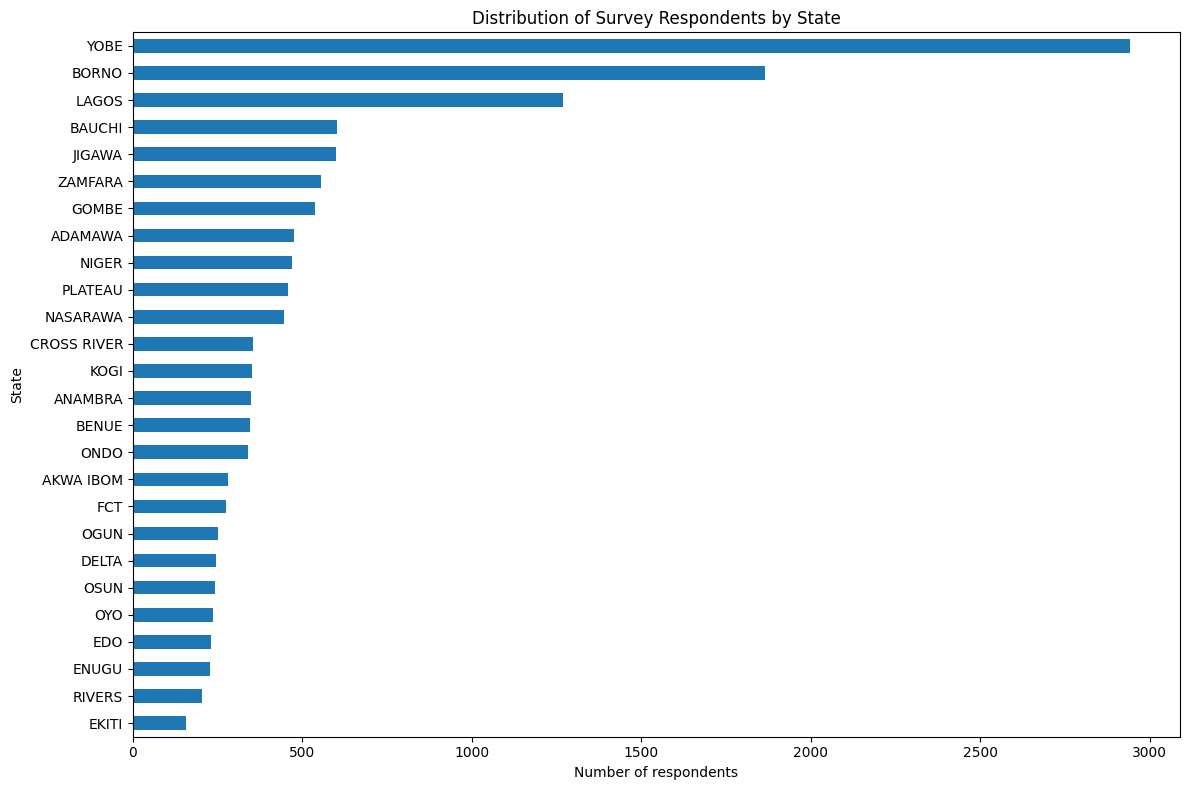

In [23]:
import matplotlib.pyplot as plt

state_counts = individual["state_name"].value_counts()

plt.figure(figsize=(12, 8))
state_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Survey Respondents by State")
plt.xlabel("Number of respondents")
plt.ylabel("State")
plt.tight_layout()
plt.show()

In [24]:
for column in ["s1a20", "s1a20c"]:
    print("\n", column)
    print(individual[column].value_counts(dropna=False))


 s1a20
s1a20
1.0     6966
NaN     5986
2.0     1327
99.0      34
Name: count, dtype: int64

 s1a20c
s1a20c
NaN     8235
1.0     4086
2.0     1901
99.0      91
Name: count, dtype: int64


In [25]:
for column in ["s1a20", "s1a20c"]:
    print("\nVariable:", column)

    labels = metadata.variable_value_labels.get(column)

    print("Response labels:", labels)


Variable: s1a20
Response labels: {1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}

Variable: s1a20c
Response labels: {1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}


In [27]:
print("Measles variable information:")
print(metadata.variable_to_label.get("s1a20"))

print("\nYellow fever variable information:")
print(metadata.variable_to_label.get("s1a20c"))

print("\nUser-defined missing values:")
print(metadata.missing_ranges)

Measles variable information:
labels11

Yellow fever variable information:
labels36

User-defined missing values:
{}


In [28]:
print("MEASLES RESPONSE LABELS:")
print(metadata.value_labels.get("labels11"))

print("\nYELLOW FEVER RESPONSE LABELS:")
print(metadata.value_labels.get("labels36"))

MEASLES RESPONSE LABELS:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}

YELLOW FEVER RESPONSE LABELS:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}


In [29]:
import pandas as pd

results = []

for column, vaccine in [
    ("s1a20", "Measles"),
    ("s1a20c", "Yellow Fever")
]:
    valid = individual[column].isin([1, 2])

    yes = (individual[column] == 1).sum()
    no = (individual[column] == 2).sum()
    total = valid.sum()

    coverage = (yes / total) * 100

    results.append({
        "Vaccine": vaccine,
        "Yes": yes,
        "No": no,
        "Valid Responses": total,
        "Coverage (%)": round(coverage, 2)
    })

coverage_table = pd.DataFrame(results)

display(coverage_table)

,Vaccine,Yes,No,Valid Responses,Coverage (%)
0,Measles,6966,1327,8293,84.00
1,Yellow Fever,4086,1901,5987,68.25


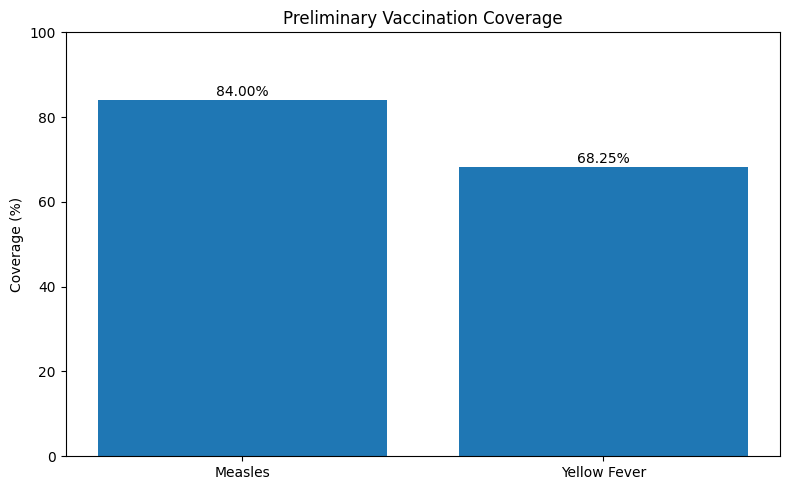

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    coverage_table["Vaccine"],
    coverage_table["Coverage (%)"]
)

plt.title("Preliminary Vaccination Coverage")
plt.ylabel("Coverage (%)")
plt.ylim(0, 100)

for i, value in enumerate(coverage_table["Coverage (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [31]:
for i, (name, label) in enumerate(
    zip(metadata.column_names, metadata.column_labels), 1
):
    print(f"{i}. {name}: {label}")

1. hm03: None
2. hm00: ZONE
3. state_code: STATE_CODE
4. state_name: STATE_NAME
5. lga_code: LGA_CODE
6. lga_name: LGA_NAME
7. ea_name: EA_NAME
8. ea_code: EA_CODE
9. sector: AREA/SECTOR
10. hm09: Household Number
11. hm21: Child Line number
12. hm22: Child Name
13. s1a09d: Day of interview
14. s1a09m: Month of interview
15. s1a09y: Year of interview
16. line_resp_child: LINE NUMBER OF RESPONDENT
17. conscent_child: Conscent
18. response_status: Response status
19. sia10h: hours
20. sia10m: minutes
21. d1a: Day
22. d1b: Month
23. d1c: Year
24. d2years: AGE IN YERAS
25. d2: Age
26. s1a16: SIA16. HAS (NAME) EVER RECEIVED ANY VACCINATIONS TO PREVENT (HIM/HER) FROM GETTI
27. s1a17: SIA17. WAS THE CHILD LIVING HERE DURING THE CAMPAIGN? (MEASLES AND MENA VACCINAT
28. sia17a: SIA17A. PLEASE SPECIFY WHERE THE CHILD WAS LIVING.
29. s1a18: SIA18 WHAT WAS THE MAIN SOURCE OF INFORMATION ABOUT THE CAMPAIGN?
30. s1a19: SIA19. WHAT WAS THE PRIMARY SOURCE OF INFORMATION ABOUT THE OCCURRENCE OF THE CA


In [32]:
print("Dataset dimensions:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

NameError: name 'df' is not defined

In [33]:
import os

print(os.listdir('/content'))

['.config', 'ROSTER.sav', 'IDENTIFICATION.sav', 'INDIVIDUAL.sav', 'sample_data']


In [34]:
import pandas as pd

df = pd.read_spss('/content/your_filename.sav')

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

PyreadstatError: File /content/your_filename.sav does not exist!

In [35]:
import os

print(os.listdir('/content'))

['.config', 'ROSTER.sav', 'IDENTIFICATION.sav', 'INDIVIDUAL.sav', 'sample_data']


In [36]:
['sample_data', 'HH Individuals.sav']

['sample_data', 'HH Individuals.sav']

In [37]:
import pandas as pd

df = pd.read_spss('/content/HH Individuals.sav')

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

PyreadstatError: File /content/HH Individuals.sav does not exist!

In [39]:
import os
print(os.listdir('/content'))

['.config', 'ROSTER.sav', 'IDENTIFICATION.sav', 'INDIVIDUAL.sav', 'sample_data']


In [41]:
import pandas as pd

df = pd.read_spss('/content/INDIVIDUAL.sav')

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

ReadstatError: Unable to convert string to the requested encoding (invalid byte sequence)

In [42]:
import pyreadstat

df, metadata = pyreadstat.read_sav(
    '/content/INDIVIDUAL.sav',
    encoding='latin1'
)

print("Dataset loaded successfully!")
print("Dataset dimensions:", df.shape)

Dataset loaded successfully!
Dataset dimensions: (14313, 65)


In [43]:
print("Measles vaccination responses:")
print(df['s1a20'].value_counts(dropna=False))

print("\nYellow fever vaccination responses:")
print(df['s1a20c'].value_counts(dropna=False))

Measles vaccination responses:
s1a20
1.0     6966
NaN     5986
2.0     1327
99.0      34
Name: count, dtype: int64

Yellow fever vaccination responses:
s1a20c
NaN     8235
1.0     4086
2.0     1901
99.0      91
Name: count, dtype: int64


In [44]:
import pandas as pd

for variable, label in [
    ('s1a20', 'Measles'),
    ('s1a20c', 'Yellow Fever')
]:

    responses = df[variable].value_counts(dropna=False)

    valid = df[variable].isin([1.0, 2.0])

    print(f"\n{label} Vaccination")
    print("Valid responses:", valid.sum())

    print(
        "Code 1 percentage:",
        round((df.loc[valid, variable] == 1.0).mean() * 100, 2),
        "%"
    )

    print(
        "Code 2 percentage:",
        round((df.loc[valid, variable] == 2.0).mean() * 100, 2),
        "%"
    )


Measles Vaccination
Valid responses: 8293
Code 1 percentage: 84.0 %
Code 2 percentage: 16.0 %

Yellow Fever Vaccination
Valid responses: 5987
Code 1 percentage: 68.25 %
Code 2 percentage: 31.75 %


In [45]:
print("Vaccination by state:")

state_analysis = df.groupby('state_name').agg(
    children=('state_name', 'size'),
    measles_responses=('s1a20', 'count'),
    yellow_fever_responses=('s1a20c', 'count')
)

print(state_analysis)

Vaccination by state:
             children  measles_responses  yellow_fever_responses
state_name                                                      
ADAMAWA           476                476                       0
AKWA IBOM         282                282                       0
ANAMBRA           347                347                       0
BAUCHI            603                603                       0
BENUE             346                345                       0
BORNO            1866                  0                    1866
CROSS RIVER       355                355                       0
DELTA             244                244                       0
EDO               229                228                       0
EKITI             158                158                       0
ENUGU             226                225                       0
FCT               274                273                       0
GOMBE             537                537                       0
JIG

In [46]:
print("MEASLES VARIABLE LABEL:")
print(metadata.column_names_to_labels.get('s1a20'))

print("\nYELLOW FEVER VARIABLE LABEL:")
print(metadata.column_names_to_labels.get('s1a20c'))

print("\nMEASLES VALUE LABELS:")
print(metadata.variable_value_labels.get('s1a20'))

print("\nYELLOW FEVER VALUE LABELS:")
print(metadata.variable_value_labels.get('s1a20c'))

MEASLES VARIABLE LABEL:
SIA20. DID THE CHILD RECEIVE THE MEASLES VACCINE DURING THE RECENT CAMPAIGN (MEA

YELLOW FEVER VARIABLE LABEL:
SIA20C. DID THE CHILD / YOU RECEIVE THE YELLOW FEVER VACCINE DURING THE RECENT C

MEASLES VALUE LABELS:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}

YELLOW FEVER VALUE LABELS:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}


In [47]:
state_summary = df.groupby('state_name').agg(
    total_children=('state_name', 'size'),
    measles_valid=('s1a20', 'count'),
    yellow_fever_valid=('s1a20c', 'count')
)

state_summary['measles_missing_pct'] = (
    1 - state_summary['measles_valid'] /
    state_summary['total_children']
) * 100

state_summary['yellow_fever_missing_pct'] = (
    1 - state_summary['yellow_fever_valid'] /
    state_summary['total_children']
) * 100

print(state_summary.round(2).to_string())

             total_children  measles_valid  yellow_fever_valid  measles_missing_pct  yellow_fever_missing_pct
state_name                                                                                                   
ADAMAWA                 476            476                   0                 0.00                     100.0
AKWA IBOM               282            282                   0                 0.00                     100.0
ANAMBRA                 347            347                   0                 0.00                     100.0
BAUCHI                  603            603                   0                 0.00                     100.0
BENUE                   346            345                   0                 0.29                     100.0
BORNO                  1866              0                1866               100.00                       0.0
CROSS RIVER             355            355                   0                 0.00                     100.0
DELTA     

In [48]:
print("MEASLES VARIABLE LABEL:")
print(metadata.column_names_to_labels.get('s1a20'))

print("\nYELLOW FEVER VARIABLE LABEL:")
print(metadata.column_names_to_labels.get('s1a20c'))

print("\nMEASLES RESPONSE CODES:")
print(metadata.variable_value_labels.get('s1a20'))

print("\nYELLOW FEVER RESPONSE CODES:")
print(metadata.variable_value_labels.get('s1a20c'))

MEASLES VARIABLE LABEL:
SIA20. DID THE CHILD RECEIVE THE MEASLES VACCINE DURING THE RECENT CAMPAIGN (MEA

YELLOW FEVER VARIABLE LABEL:
SIA20C. DID THE CHILD / YOU RECEIVE THE YELLOW FEVER VACCINE DURING THE RECENT C

MEASLES RESPONSE CODES:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}

YELLOW FEVER RESPONSE CODES:
{1.0: 'Yes', 2.0: 'No', 99.0: 'Don?t know'}


In [49]:
print("POSSIBLE WEIGHT AND SURVEY DESIGN VARIABLES:")

for col in df.columns:
    if any(word in col.lower() for word in
           ['weight', 'wt', 'strata', 'psu', 'cluster']):
        print(
            col,
            ":", metadata.column_names_to_labels.get(col, "No label")
        )

POSSIBLE WEIGHT AND SURVEY DESIGN VARIABLES:


In [50]:
for col in df.columns:
    print(col, ":", metadata.column_names_to_labels.get(col, "No label"))

hm03 : None
hm00 : ZONE
state_code : STATE_CODE
state_name : STATE_NAME
lga_code : LGA_CODE
lga_name : LGA_NAME
ea_name : EA_NAME
ea_code : EA_CODE
sector : AREA/SECTOR
hm09 : Household Number
hm21 : Child Line number
hm22 : Child Name
s1a09d : Day of interview
s1a09m : Month of interview
s1a09y : Year of interview
line_resp_child : LINE NUMBER OF RESPONDENT
conscent_child : Conscent
response_status : Response status
sia10h : hours
sia10m : minutes
d1a : Day
d1b : Month
d1c : Year
d2years : AGE IN YERAS
d2 : Age
s1a16 : SIA16. HAS (NAME) EVER RECEIVED ANY VACCINATIONS TO PREVENT (HIM/HER) FROM GETTI
s1a17 : SIA17. WAS THE CHILD LIVING HERE DURING THE CAMPAIGN? (MEASLES AND MENA VACCINAT
sia17a : SIA17A. PLEASE SPECIFY WHERE THE CHILD WAS LIVING.
s1a18 : SIA18 WHAT WAS THE MAIN SOURCE OF INFORMATION ABOUT THE CAMPAIGN?
s1a19 : SIA19. WHAT WAS THE PRIMARY SOURCE OF INFORMATION ABOUT THE OCCURRENCE OF THE CA
s1a20 : SIA20. DID THE CHILD RECEIVE THE MEASLES VACCINE DURING THE RECENT CAMPAI

In [51]:
print("HM03 DETAILS")
print("Variable label:", metadata.column_names_to_labels.get('hm03'))
print("Value labels:", metadata.variable_value_labels.get('hm03'))
print("Unique values:", df['hm03'].dropna().unique()[:20])

print("\nDATASET INFORMATION")
print("Rows:", metadata.number_rows)
print("Columns:", metadata.number_columns)
print("File label:", metadata.file_label)

print("\nAVAILABLE METADATA")
print([x for x in dir(metadata) if not x.startswith('_')])

HM03 DETAILS
Variable label: None
Value labels: None
Unique values: [17. 28. 29. 34. 46. 70. 80. 81. 82. 83. 84. 85. 86. 87. 88. 89. 90. 93.
 94. 95.]

DATASET INFORMATION
Rows: 14313
Columns: 65
File label: None

AVAILABLE METADATA
['column_labels', 'column_names', 'column_names_to_labels', 'creation_time', 'file_encoding', 'file_format', 'file_label', 'missing_ranges', 'missing_user_values', 'modification_time', 'mr_sets', 'notes', 'number_columns', 'number_rows', 'original_variable_informats', 'original_variable_types', 'readstat_variable_types', 'table_name', 'value_labels', 'variable_alignment', 'variable_display_width', 'variable_measure', 'variable_storage_width', 'variable_to_label', 'variable_value_labels']


In [52]:
print("DATA TYPES AND MISSING VALUES")

data_check = pd.DataFrame({
    'Variable': df.columns,
    'Data_Type': df.dtypes.astype(str).values,
    'Missing_Count': df.isna().sum().values,
    'Missing_Percentage': (
        df.isna().mean().values * 100
    ).round(2)
})

print(data_check.to_string(index=False))

DATA TYPES AND MISSING VALUES
       Variable Data_Type  Missing_Count  Missing_Percentage
           hm03   float64              0                0.00
           hm00   float64              0                0.00
     state_code   float64              0                0.00
     state_name    object              0                0.00
       lga_code   float64              0                0.00
       lga_name    object              0                0.00
        ea_name    object              0                0.00
        ea_code    object              0                0.00
         sector   float64              0                0.00
           hm09   float64              0                0.00
           hm21   float64              0                0.00
           hm22    object              0                0.00
         s1a09d   float64              0                0.00
         s1a09m   float64              0                0.00
         s1a09y   float64              0               

In [53]:
print("MEASLES VACCINATION DISTRIBUTION")
print(df['s1a20'].value_counts(dropna=False).sort_index())

print("\nYELLOW FEVER VACCINATION DISTRIBUTION")
print(df['s1a20c'].value_counts(dropna=False).sort_index())

print("\nMEASLES VALID RESPONSES")
print(df['s1a20'].notna().sum())

print("\nYELLOW FEVER VALID RESPONSES")
print(df['s1a20c'].notna().sum())

MEASLES VACCINATION DISTRIBUTION
s1a20
1.0     6966
2.0     1327
99.0      34
NaN     5986
Name: count, dtype: int64

YELLOW FEVER VACCINATION DISTRIBUTION
s1a20c
1.0     4086
2.0     1901
99.0      91
NaN     8235
Name: count, dtype: int64

MEASLES VALID RESPONSES
8327

YELLOW FEVER VALID RESPONSES
6078


In [54]:
# Create separate analytical datasets
measles_df = df[df['s1a20'].isin([1, 2])].copy()

yellow_fever_df = df[df['s1a20c'].isin([1, 2])].copy()

# Convert outcomes to binary values
# 1 = Vaccinated
# 0 = Not vaccinated

measles_df['vaccinated'] = (
    measles_df['s1a20'] == 1
).astype(int)

yellow_fever_df['vaccinated'] = (
    yellow_fever_df['s1a20c'] == 1
).astype(int)

print("MEASLES ANALYTICAL DATASET")
print("Records:", len(measles_df))
print(measles_df['vaccinated'].value_counts())

print("\nYELLOW FEVER ANALYTICAL DATASET")
print("Records:", len(yellow_fever_df))
print(yellow_fever_df['vaccinated'].value_counts())

MEASLES ANALYTICAL DATASET
Records: 8293
vaccinated
1    6966
0    1327
Name: count, dtype: int64

YELLOW FEVER ANALYTICAL DATASET
Records: 5987
vaccinated
1    4086
0    1901
Name: count, dtype: int64


In [55]:
print("MEASLES AGE SUMMARY")
print(measles_df['d2years'].describe())

print("\nYELLOW FEVER AGE SUMMARY")
print(yellow_fever_df['d2years'].describe())

print("\nMEASLES AGE BY VACCINATION STATUS")
print(
    measles_df.groupby('vaccinated')['d2years']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

print("\nYELLOW FEVER AGE BY VACCINATION STATUS")
print(
    yellow_fever_df.groupby('vaccinated')['d2years']
    .agg(['count', 'mean', 'median', 'min', 'max'])
)

MEASLES AGE SUMMARY
count    8293.000000
mean        2.565055
std         1.176539
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max        11.000000
Name: d2years, dtype: float64

YELLOW FEVER AGE SUMMARY
count    5987.000000
mean       17.968766
std        12.255924
min         0.000000
25%         7.000000
50%        15.000000
75%        28.000000
max        45.000000
Name: d2years, dtype: float64

MEASLES AGE BY VACCINATION STATUS
            count      mean  median  min   max
vaccinated                                    
0            1327  2.458930     3.0  0.0  11.0
1            6966  2.585271     3.0  0.0   6.0

YELLOW FEVER AGE BY VACCINATION STATUS
            count       mean  median  min   max
vaccinated                                     
0            1901  20.813256    20.0  0.0  44.0
1            4086  16.645374    14.0  0.0  45.0


In [56]:
print("AGE VARIABLE LABEL")
print(metadata.column_names_to_labels.get('d2years'))

print("\nAGE FREQUENCIES - MEASLES")
print(measles_df['d2years'].value_counts().sort_index())

print("\nAGE FREQUENCIES - YELLOW FEVER")
print(yellow_fever_df['d2years'].value_counts().sort_index())

print("\nAGE BY VACCINATION STATUS - YELLOW FEVER")
print(
    yellow_fever_df.groupby('vaccinated')['d2years']
    .value_counts().sort_index().to_string()
)

AGE VARIABLE LABEL
AGE IN YERAS

AGE FREQUENCIES - MEASLES
d2years
0.0      240
1.0     1604
2.0     2042
3.0     2055
4.0     2348
5.0        2
6.0        1
11.0       1
Name: count, dtype: int64

AGE FREQUENCIES - YELLOW FEVER
d2years
0.0      30
1.0     137
2.0     203
3.0     213
4.0     208
5.0     266
6.0     232
7.0     252
8.0     228
9.0     187
10.0    252
11.0    140
12.0    175
13.0    173
14.0    155
15.0    197
16.0    127
17.0    113
18.0    139
19.0     86
20.0    207
21.0     71
22.0     98
23.0     66
24.0    119
25.0    227
26.0     91
27.0     76
28.0     92
29.0     51
30.0    246
31.0     48
32.0     74
33.0     73
34.0     78
35.0    181
36.0     59
37.0     58
38.0     89
39.0     60
40.0    186
41.0     34
42.0     64
43.0     51
44.0     74
45.0      1
Name: count, dtype: int64

AGE BY VACCINATION STATUS - YELLOW FEVER
vaccinated  d2years
0           0.0          7
            1.0         42
            2.0         46
            3.0         49
            4.0

In [57]:
print("ORIGINAL AGE VARIABLE: d2")

print("\nMEASLES AGE VALUES")
print(measles_df['d2'].value_counts(dropna=False).sort_index())

print("\nYELLOW FEVER AGE VALUES")
print(yellow_fever_df['d2'].value_counts(dropna=False).sort_index())

print("\nUNUSUAL MEASLES AGE RECORDS")
print(
    measles_df.loc[
        measles_df['d2years'] > 4,
        ['state_name', 'lga_name', 'd1a', 'd1b',
         'd1c', 'd2', 'd2years']
    ].to_string(index=False)
)

ORIGINAL AGE VARIABLE: d2

MEASLES AGE VALUES
d2
0.0       1
1.0       3
2.0       2
3.0       1
4.0       2
5.0       3
9.0     117
10.0    106
11.0    146
12.0    186
13.0    138
14.0    148
15.0    125
16.0    131
17.0    145
18.0    129
19.0    124
20.0    130
21.0    110
22.0    100
23.0    146
24.0    205
25.0    218
26.0    214
27.0    184
28.0    175
29.0    147
30.0    156
31.0    180
32.0    164
33.0    161
34.0    105
35.0    124
36.0    223
37.0    192
38.0    198
39.0    203
40.0    164
41.0    159
42.0    183
43.0    208
44.0    146
45.0    145
46.0     94
47.0    156
48.0    261
49.0    233
50.0    200
51.0    177
52.0    213
53.0    209
54.0    189
55.0    232
56.0    197
57.0    182
58.0     91
59.0     12
Name: count, dtype: int64

YELLOW FEVER AGE VALUES
d2
9.0       12
10.0      12
11.0      12
12.0      16
13.0      14
14.0      15
15.0      11
16.0      16
17.0      11
18.0       4
19.0       6
20.0      13
21.0       7
22.0       6
23.0      18
24.0      14
25.0 

In [58]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Candidate predictors
features = [
    'd2years',
    'state_name',
    'sector',
    's1a16',
    's1a17',
    's1a18',
    's1a19'
]

def run_model(data, project_name):

    # Select available predictors
    X = data[features].copy()
    y = data['vaccinated'].copy()

    # Separate numerical and categorical variables
    numeric_features = ['d2years']
    categorical_features = [
        col for col in features
        if col not in numeric_features
    ]

    # Convert categorical variables to strings
    for col in categorical_features:
        X[col] = X[col].astype('string').fillna('Missing').astype(str)

    # Preprocessing
    preprocessor = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'),
         numeric_features),

        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_features)
    ])

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Baseline model
    baseline = DummyClassifier(strategy='most_frequent')
    baseline.fit(X_train, y_train)
    baseline_predictions = baseline.predict(X_test)

    # Random Forest
    model = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=150,
            max_depth=12,
            min_samples_split=5,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\n" + "=" * 55)
    print(project_name)
    print("=" * 55)

    print("\nBASELINE ACCURACY:",
          round(accuracy_score(y_test, baseline_predictions), 4))

    print("\nRANDOM FOREST RESULTS")
    print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
    print("Precision:", round(precision_score(
        y_test, predictions, zero_division=0), 4))
    print("Recall:", round(recall_score(
        y_test, predictions, zero_division=0), 4))
    print("F1 Score:", round(f1_score(
        y_test, predictions, zero_division=0), 4))

    print("\nCLASSIFICATION REPORT")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    print("CONFUSION MATRIX")
    print(confusion_matrix(y_test, predictions))

    return model

# Train separate models
measles_model = run_model(
    measles_df,
    "MEASLES VACCINATION PREDICTION"
)

yellow_fever_model = run_model(
    yellow_fever_df,
    "YELLOW FEVER VACCINATION PREDICTION"
)


MEASLES VACCINATION PREDICTION

BASELINE ACCURACY: 0.8403

RANDOM FOREST RESULTS
Accuracy: 0.8987
Precision: 0.9323
Recall: 0.9484
F1 Score: 0.9403

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.70      0.64      0.67       265
           1       0.93      0.95      0.94      1394

    accuracy                           0.90      1659
   macro avg       0.82      0.79      0.80      1659
weighted avg       0.90      0.90      0.90      1659

CONFUSION MATRIX
[[ 169   96]
 [  72 1322]]

YELLOW FEVER VACCINATION PREDICTION

BASELINE ACCURACY: 0.6828

RANDOM FOREST RESULTS
Accuracy: 0.8514
Precision: 0.9167
Recall: 0.8606
F1 Score: 0.8878

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       380
           1       0.92      0.86      0.89       818

    accuracy                           0.85      1198
   macro avg       0.83      0.85      0.83      1198
weighted